# 01 – Pre-training on public review logs

**Question:** can a model we train ourselves predict recall better than FSRS, the
algorithm that schedules our cards today?

We do not have much personal data yet, so this notebook uses ~1.5 million real Anki
reviews from five users ([open-spaced-repetition/fsrs-dataset](https://huggingface.co/datasets/open-spaced-repetition/fsrs-dataset), MIT).
The features come from the **same feature function** the app will use
(`forglemmigej_api.features`), so whatever we learn here carries over.

Steps:
1. Look at the data (and see the forgetting curve).
2. Split it **chronologically**: older reviews to train, the most recent ones to test.
3. Baselines: a constant guess, and FSRS's own prediction.
4. Challengers: logistic regression, then LightGBM.
5. Compare them with log loss, AUC and calibration.

The dataset is built with `uv run --group ml python -m forglemmigej_api.training.build_public`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from forglemmigej_api.features import HISTORY_FEATURES
from forglemmigej_api.training.evaluate import calibration_table, chronological_split, score
from forglemmigej_api.training.models import fit_lightgbm, fit_logistic, predict

pd.set_option("display.precision", 4)
DATA = Path("../data/processed/public_examples.parquet")
data = pd.read_parquet(DATA)
data["recalled"] = data["recalled"].astype(int)
print(f"{len(data):,} examples, {data['user'].nunique()} users, {data['card_id'].nunique():,} cards")
data.head()

1,342,112 examples, 5 users, 170,871 cards


,user,card_id,reviewed_at,recalled,elapsed_days,log_elapsed_days,n_reviews,n_lapses,last_recalled,recall_rate,success_streak,prev_interval_days,days_since_first,log_last_response_s,fsrs_recall
0,05ff595,05ff595:1469701510736,2019-04-18 23:41:27.067000+00:00,1,0.3872,0.3273,1.0,1.0,0.0,0.0000,0.0,0.0000,0.3872,NaN,1.0000
1,05ff595,05ff595:1469701510736,2019-04-22 23:30:42.957000+00:00,1,3.9925,1.6079,2.0,1.0,1.0,0.5000,1.0,0.3872,4.3797,NaN,0.6740
2,05ff595,05ff595:1469701510736,2019-05-01 00:12:10.440000+00:00,1,8.0288,2.2004,3.0,1.0,1.0,0.6667,2.0,3.9925,12.4085,NaN,0.8205
3,05ff595,05ff595:1469701510736,2019-05-22 23:35:37.997000+00:00,1,21.9746,3.1344,4.0,1.0,1.0,0.7500,3.0,8.0288,34.3831,NaN,0.8728
4,05ff595,05ff595:1469701510736,2019-07-15 02:50:44.490000+00:00,0,53.1355,3.9915,5.0,1.0,1.0,0.8000,4.0,21.9746,87.5186,NaN,0.8872


## 1. The data

Each row is one review of a card that had been seen before. `recalled` is the label
(1 = remembered). Everything else is a feature, computed only from the reviews
*before* that row.

First: how often are cards remembered at all? If 90% are, a model that always says
"0.9" is already right 90% of the time. That is why we compare against baselines
and do not look at accuracy.

In [2]:
summary = data.groupby("user").agg(
    examples=("recalled", "size"),
    recall_rate=("recalled", "mean"),
    first=("reviewed_at", "min"),
    last=("reviewed_at", "max"),
)
summary

,examples,recall_rate,first,last
user,,,,
05ff595,445661,0.9757,2017-06-06 07:18:11.118000+00:00,2023-07-14 06:59:59.821000+00:00
23e35f5,211696,0.8434,2020-12-08 07:09:56.400000+00:00,2022-10-22 20:15:01.595000+00:00
27e8453,85892,0.9272,2022-01-14 03:18:48.474000+00:00,2023-08-06 03:23:28.619000+00:00
4181a16,380867,0.8843,2017-11-22 17:11:36.535000+00:00,2023-03-04 19:51:29.988000+00:00
48a935a,217996,0.8283,2021-06-12 07:05:33.797000+00:00,2023-08-14 16:36:08.032000+00:00


### The forgetting curve

The single most important feature is the time since the last review. Grouping
reviews by elapsed days shows the classic forgetting curve: the longer the gap,
the lower the chance of recall. (Cards that are reviewed after long gaps are also
the well-known ones, which is why the curve flattens: the scheduler only waits
long for strong memories.)

,mean,size
gap,,
<0.5,0.9520,17953
0.5-1,0.9042,108521
1-2,0.8914,136813
2-4,0.9193,173572
4-7,0.9268,148131
7-14,0.9116,169532
14-30,0.8971,170136
30-60,0.8802,122807
60-120,0.8802,107211


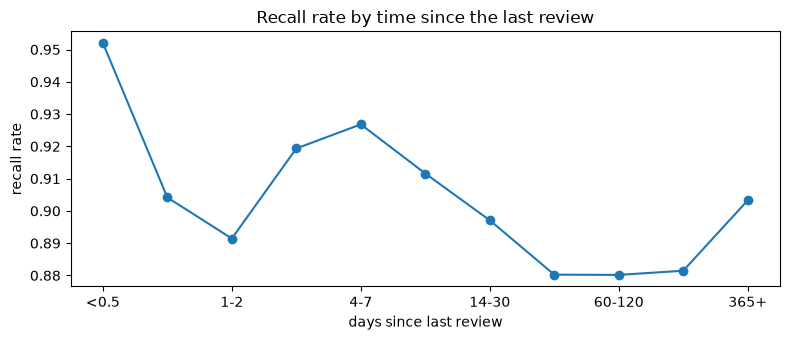

In [3]:
buckets = [0, 0.5, 1, 2, 4, 7, 14, 30, 60, 120, 365, 10_000]
labels = ["<0.5", "0.5-1", "1-2", "2-4", "4-7", "7-14", "14-30", "30-60", "60-120", "120-365", "365+"]
curve = (
    data.assign(gap=pd.cut(data["elapsed_days"], buckets, labels=labels, right=False))
    .groupby("gap", observed=True)["recalled"]
    .agg(["mean", "size"])
)
ax = curve["mean"].plot(marker="o", figsize=(8, 3.5), ylabel="recall rate", xlabel="days since last review")
ax.set_title("Recall rate by time since the last review")
plt.tight_layout()
curve

## 2. Chronological split

We train on each user's older reviews and test on their most recent 20%. A random
split would let the model learn from the future (e.g. from later reviews of the
same card), which looks great in a notebook and fails in production.

In [4]:
train, test = chronological_split(data, test_fraction=0.2, group="user")
print(f"train: {len(train):,}   test: {len(test):,}")
# The public data has no response times, so that feature is always missing here.
FEATURES = [f for f in HISTORY_FEATURES if f != "log_last_response_s"]
FEATURES

train: 1,073,689   test: 268,423


['elapsed_days',
 'log_elapsed_days',
 'n_reviews',
 'n_lapses',
 'last_recalled',
 'recall_rate',
 'success_streak',
 'prev_interval_days',
 'days_since_first',
 'fsrs_recall']

## 3. Baselines

- **Constant:** always predict the training set's average recall rate. Any useful
  model must beat this.
- **FSRS:** the `fsrs_recall` feature *is* FSRS's prediction (default parameters,
  replayed from the history), the same model that is the champion in the app.

In [5]:
predictions = {
    "constant": np.full(len(test), train["recalled"].mean()),
    "FSRS (champion)": test["fsrs_recall"].to_numpy(),
}

## 4. Challengers

**Logistic regression** adds up the features, each with a learned weight, and turns
the sum into a probability. It is simple and its weights can be read.

**LightGBM** builds many small decision trees, each correcting the previous ones.
It can learn interactions ("a long gap matters more for a card that was forgotten
before") that a weighted sum cannot.

In [6]:
logistic = fit_logistic(train, FEATURES)
predictions["logistic regression"] = predict(logistic, test, FEATURES)

lightgbm = fit_lightgbm(train, FEATURES)
predictions["LightGBM"] = predict(lightgbm, test, FEATURES)

without_fsrs = [f for f in FEATURES if f != "fsrs_recall"]
lightgbm_plain = fit_lightgbm(train, without_fsrs)
predictions["LightGBM without FSRS feature"] = predict(lightgbm_plain, test, without_fsrs)
print("LightGBM trees used:", lightgbm.best_iteration_, "/", lightgbm_plain.best_iteration_)

LightGBM trees used: 25 / 22


## 5. Results

Lower is better for log loss, Brier and RMSE (bins); higher is better for AUC.

In [7]:
results = pd.DataFrame(
    {name: score(test["recalled"], p).as_dict() for name, p in predictions.items()}
).T.drop(columns="n")
results.sort_values("log_loss")

,log_loss,brier,auc,rmse_bins
LightGBM,0.3339,0.0968,0.6936,0.0270
LightGBM without FSRS feature,0.3367,0.0975,0.6871,0.0275
logistic regression,0.3395,0.0982,0.6777,0.0297
constant,0.3588,0.1020,0.5000,0.0208
FSRS (champion),0.4054,0.0994,0.6453,0.0359


### Calibration

If a model says 80%, are about 80% of those cards remembered? Points on the
diagonal mean well-calibrated probabilities. This matters for us because the
scheduler acts on the probability itself (a card is due when it drops below 90%).

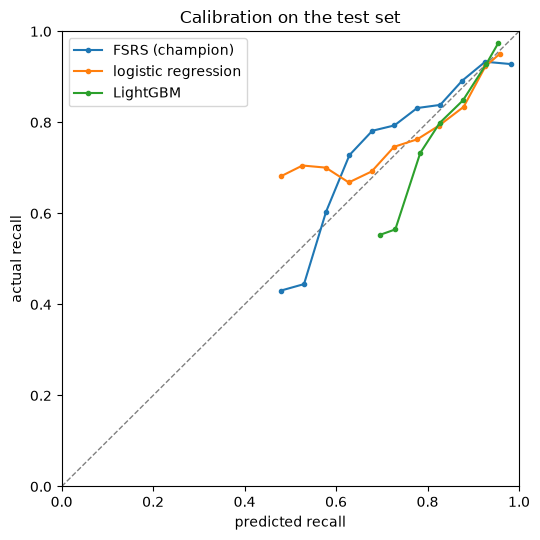

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", linewidth=1)
for name in ["FSRS (champion)", "logistic regression", "LightGBM"]:
    table = calibration_table(test["recalled"], predictions[name])
    table = table[table["n"] >= 200]
    ax.plot(table["predicted"], table["actual"], marker="o", markersize=3, label=name)
ax.set(xlabel="predicted recall", ylabel="actual recall", title="Calibration on the test set", xlim=(0, 1), ylim=(0, 1))
ax.legend()
plt.tight_layout()

### Per user

An average can hide that a model helps some users and hurts others. The promotion
gate will look at exactly one user (the learner), so it is worth seeing how stable
the difference is.

In [9]:
per_user = []
for user, part in test.groupby("user"):
    index = test.index.get_indexer(part.index)
    row = {"user": user, "n": len(part)}
    for name in ["FSRS (champion)", "logistic regression", "LightGBM"]:
        row[name] = score(part["recalled"], predictions[name][index]).log_loss
    per_user.append(row)
per_user = pd.DataFrame(per_user).set_index("user")
per_user["LightGBM better than FSRS"] = per_user["LightGBM"] < per_user["FSRS (champion)"]
per_user

,n,FSRS (champion),logistic regression,LightGBM,LightGBM better than FSRS
user,,,,,
05ff595,89132,0.1940,0.1712,0.1693,True
23e35f5,42339,0.6548,0.4804,0.4621,True
27e8453,17179,0.4663,0.3122,0.3068,True
4181a16,76174,0.4204,0.3972,0.3905,True
48a935a,43599,0.5450,0.4568,0.4577,True


### What did the models learn?

Logistic regression weights (features are standardised, so the sizes are
comparable): positive means "more of this, more likely remembered".
LightGBM's importance counts how much each feature reduced the error.

In [10]:
weights = pd.Series(logistic[-1].coef_[0], index=FEATURES).sort_values()
importance = pd.Series(lightgbm.booster_.feature_importance("gain"), index=FEATURES)
pd.DataFrame({"logistic weight": weights, "LightGBM gain share": importance / importance.sum()}).sort_values(
    "LightGBM gain share", ascending=False
)

,logistic weight,LightGBM gain share
n_lapses,-0.0797,0.3628
recall_rate,0.2348,0.1884
fsrs_recall,0.2853,0.1793
days_since_first,0.0851,0.0746
elapsed_days,0.1093,0.0663
n_reviews,-0.1721,0.0616
success_streak,-0.1375,0.0244
log_elapsed_days,-0.1428,0.0212
prev_interval_days,-0.0894,0.0156
last_recalled,0.0506,0.0058


## Conclusions

Test set: the most recent 20% of each user's reviews (268k reviews from 5 users).

| model | log loss | AUC |
|---|---|---|
| LightGBM | **0.334** | **0.694** |
| LightGBM without the FSRS feature | 0.337 | 0.687 |
| logistic regression | 0.340 | 0.678 |
| constant guess | 0.359 | 0.500 |
| FSRS, default parameters | 0.405 | 0.645 |

1. **The trained challengers beat both baselines, for every one of the five users.** LightGBM is about 7% better than a constant guess and 18% better than default FSRS on log loss.
2. **Default FSRS loses to a constant guess on log loss.** It ranks cards reasonably (AUC 0.65), but its probabilities do not fit these users: the calibration plot shows it is underconfident in the middle range and overconfident at the top, where most reviews are. FSRS is meant to be *fitted to each user*. So this comparison flatters our models. **The fair next opponent is FSRS with per-user parameters**, which is the first planned challenger anyway.
3. **LightGBM is only a little better than logistic regression.** Most of the signal is in a few simple features. FSRS's own prediction helps as a feature (0.337 → 0.334).
4. **Card difficulty matters most:** the number of lapses and the card's recall rate so far carry most of LightGBM's gain. Elapsed time matters less than expected, because the scheduler only waits long for cards it already considers strong.
5. **The forgetting curve looks flat** for the same reason (scheduler bias): the data only shows what the scheduler chose to ask. This is the bias noted in the design document, and why models are compared on the same reviews.
6. **Metric caveat:** the constant guess has the lowest binned calibration error, because all its predictions fall into one bin, whose average is close to the overall recall rate. Calibration error alone cannot pick a model; it is read together with log loss and AUC.

**What this means for forglemmigej:** the pipeline (shared features → chronological split → models → metrics) works at scale. Before a challenger can replace FSRS in the app, it has to beat FSRS *fitted to the learner*, on the learner's own reviews.
